# Tugas 3: Clustering Multimodal Tipe Material
Data: `clustering.npz` (gambar 64x64 + spektrum 128) dan `clustering_meta.csv`. Tanpa label; jumlah tipe material tidak diketahui. Skor akhir = ARI terhadap label tersembunyi.

**Alur:** 0 Setup → 1 Muat data → 2 Eksplorasi → 3 Praproses + augmentasi → 4 Representasi tanpa label → 5 Fusi dua modalitas → 6 Jumlah klaster → 7 Perbandingan metode (KMeans, GMM, DEC) → 8 Analisis modalitas → 9 Visualisasi → 10 `cluster.csv`

Jalankan sel dari atas ke bawah. Sel bagian 4 paling lama (pelatihan).

## 0. Setup dan parameter

In [1]:
import os, time, platform
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
from utils3 import *

set_seed(SEED)
DATA_DIR = '../../data/data_uts_dl'
OUT_DIR = 'hasil_t3'; os.makedirs(OUT_DIR, exist_ok=True)

# --- parameter yang boleh diubah ---
EPOCHS, SPE, BATCH = 20, 12000, 256   # pelatihan: epoch, sampel per epoch, batch. CPU lambat -> EPOCHS=10
RETRAIN = True                        # False = pakai embedding tersimpan di hasil_t3/embeddings.npz bila ada
N_PCA = 32                            # dimensi fitur gabungan sebelum clustering
K_MIN, K_MAX = 2, 15                  # rentang jumlah klaster yang dicari
N_VIS = 15000                         # jumlah titik untuk UMAP/t-SNE

print('python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__, '| torch', torch.__version__, '| device', DEVICE)

python 3.13.0 | numpy 2.2.1 | pandas 3.1.1 | torch 2.15.0+cpu | device cpu


## 1. Muat data

In [2]:
img_raw, spec_raw, meta = load_data(DATA_DIR)
print('gambar', img_raw.shape, img_raw.dtype, '| spektrum', spec_raw.shape, spec_raw.dtype)
print(meta.head()); print(meta.dtypes)
assert 'id_sampel' in meta.columns, meta.columns.tolist()

gambar (36000, 64, 64) uint8 | spektrum (36000, 128) float32
   indeks id_sampel mikroskop
0       0   S966119        M1
1       1   S315633        M2
2       2   S805122        M1
3       3   S467543        M1
4       4   S475842        M1
indeks       int64
id_sampel      str
mikroskop      str
dtype: object


## 2. Eksplorasi (checklist #30)
- [ ] 2a ringkasan dan mikroskop  - [ ] 2b distorsi gambar  - [ ] 2c distorsi spektrum  - [ ] 2d baseline klasik pada fitur mentah

Catat temuan untuk laporan: beda antar mikroskop, bentuk distorsi, dan seberapa besar fitur mentah dipengaruhi mikroskop.

### 2a. Ringkasan

In [3]:
print('NaN gambar:', int(np.isnan(img_raw.astype(float)).sum()), '| NaN spektrum:', int((~np.isfinite(spec_raw)).sum()))
print('id_sampel unik:', meta['id_sampel'].is_unique)
print(meta['mikroskop'].value_counts().to_string())
mik = meta['mikroskop'].to_numpy()

stat = pd.DataFrame({'mikroskop': mik, 'rerata_gambar': img_raw.mean((1, 2)), 'std_gambar': img_raw.std((1, 2)),
                     'rerata_spektrum': np.nanmean(spec_raw, 1), 'std_spektrum': np.nanstd(spec_raw, 1)})
print(stat.groupby('mikroskop').agg(['mean', 'std']).round(3).T.to_string())

NaN gambar: 0 | NaN spektrum: 0
id_sampel unik: True
mikroskop
M1    21636
M2    14364
mikroskop                  M1       M2
rerata_gambar   mean  127.795  146.068
                std    12.061   11.023
std_gambar      mean   19.698   19.902
                std     5.377    4.650
rerata_spektrum mean    0.449    0.447
                std     0.254    0.254
std_spektrum    mean    0.303    0.305
                std     0.094    0.095


### 2b. Distorsi gambar (rotasi, skala, brightness, beda mikroskop)

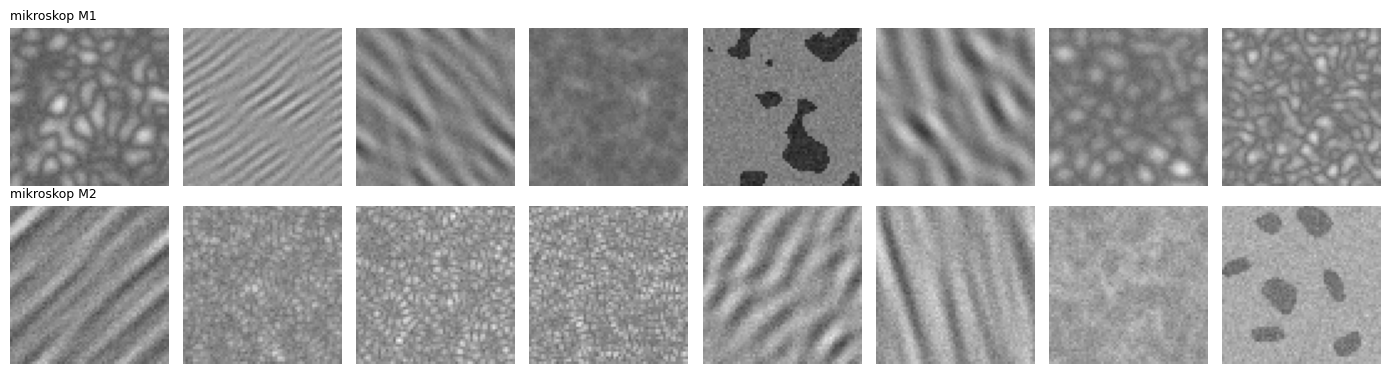

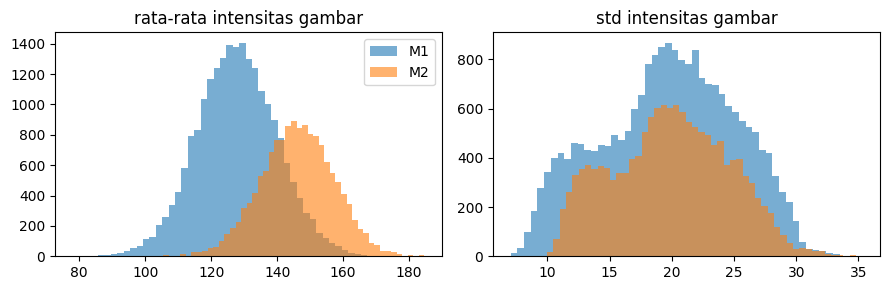

In [4]:
rng = np.random.RandomState(SEED)
fig, ax = plt.subplots(2, 8, figsize=(14, 3.8))
for r, m in enumerate(sorted(np.unique(mik))[:2]):
    ids = rng.choice(np.flatnonzero(mik == m), 8, replace=False)
    for c, i in enumerate(ids):
        ax[r, c].imshow(img_raw[i], cmap='gray', vmin=0, vmax=255); ax[r, c].axis('off')
    ax[r, 0].set_title(f'mikroskop {m}', fontsize=9, loc='left')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/contoh_gambar.png', dpi=130); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for m in np.unique(mik):
    ax[0].hist(stat.loc[stat.mikroskop == m, 'rerata_gambar'], bins=50, alpha=.6, label=m)
    ax[1].hist(stat.loc[stat.mikroskop == m, 'std_gambar'], bins=50, alpha=.6, label=m)
ax[0].set_title('rata-rata intensitas gambar'); ax[1].set_title('std intensitas gambar'); ax[0].legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/intensitas_per_mikroskop.png', dpi=130); plt.show()

### 2c. Distorsi spektrum (geser, baseline, spike)

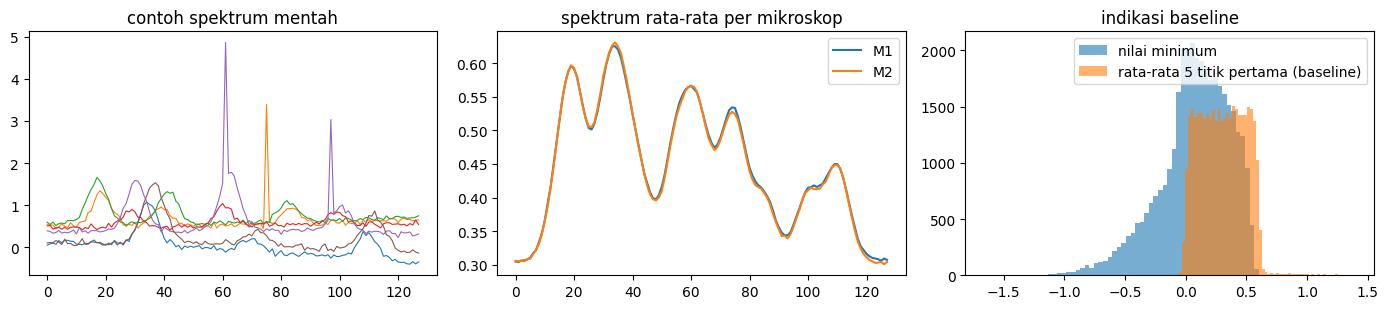

% spektrum dengan minimal 1 outlier terisolasi (spike atau derau ekstrem): 74.9 | rata-rata per spektrum: 1.82


In [5]:
s0 = np.nan_to_num(spec_raw)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
for i in rng.choice(len(s0), 6, replace=False): ax[0].plot(s0[i], lw=.8)
ax[0].set_title('contoh spektrum mentah')
for m in np.unique(mik): ax[1].plot(s0[mik == m].mean(0), label=m)
ax[1].set_title('spektrum rata-rata per mikroskop'); ax[1].legend()
ax[2].hist(s0.min(1), bins=60, alpha=.6, label='nilai minimum'); ax[2].hist(s0[:, :5].mean(1), bins=60, alpha=.6, label='rata-rata 5 titik pertama (baseline)')
ax[2].legend(); ax[2].set_title('indikasi baseline')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/contoh_spektrum.png', dpi=130); plt.show()

mask, _ = find_spikes(s0)
print('% spektrum dengan minimal 1 outlier terisolasi (spike atau derau ekstrem):', round(float(mask.any(1).mean() * 100), 1),
      '| rata-rata per spektrum:', round(float(mask.sum(1).mean()), 2))

### 2d. Baseline klasik pada fitur mentah (PCA piksel + spektrum, KMeans)
Jika klaster mentah sangat berkaitan dengan mikroskop (NMI tinggi), itu tanda distorsi/domain shift mendominasi dan representasi perlu dibuat invarian.

In [6]:
from sklearn.decomposition import PCA
raw_img = (img_raw.reshape(len(img_raw), -1) / 255.0).astype(np.float32)
raw_img = (raw_img - raw_img.mean(1, keepdims=True)) / (raw_img.std(1, keepdims=True) + 1e-6)
pc_img = PCA(32, svd_solver='randomized', random_state=SEED).fit_transform(raw_img)
pc_spec = PCA(16, random_state=SEED).fit_transform((s0 - s0.mean(1, keepdims=True)) / (s0.std(1, keepdims=True) + 1e-6))
Z_raw = make_features([pc_img, pc_spec], n_pca=None)
mik_id = encode_categories(mik)
for k in (4, 6, 8):
    lab = cluster_kmeans(Z_raw, k)
    print(f'KMeans fitur mentah k={k}: NMI(klaster, mikroskop) = {normalized_mutual_info_score(lab, mik_id):.3f}')
del raw_img

KMeans fitur mentah k=4: NMI(klaster, mikroskop) = 0.000
KMeans fitur mentah k=6: NMI(klaster, mikroskop) = 0.000
KMeans fitur mentah k=8: NMI(klaster, mikroskop) = 0.000


## 3. Praproses dan augmentasi
Gambar: z-score per gambar (meredam beda brightness/kontras). Spektrum: isi NaN, buang spike satu-titik, z-score per spektrum.

**Augmentasi** (untuk pembelajaran kontrastif; setiap augmentasi meniru satu distorsi di soal, sehingga model belajar mengabaikannya):
| Modalitas | Augmentasi | Alasan |
|---|---|---|
| Gambar | rotasi bebas, flip, skala ±30%, translasi | rotasi dan skala adalah distorsi |
| Gambar | brightness dan kontras acak, blur 3×3, derau | beda mikroskop, brightness |
| Spektrum | geser ±5 bin dan regang ±3% | spektrum bergeser |
| Spektrum | baseline polinomial orde 2, skala | baseline melayang |
| Spektrum | spike acak, derau | spike |

gambar (36000, 1, 64, 64) | spektrum (36000, 1, 128) | rata-rata/std gambar: 0.0 1.0


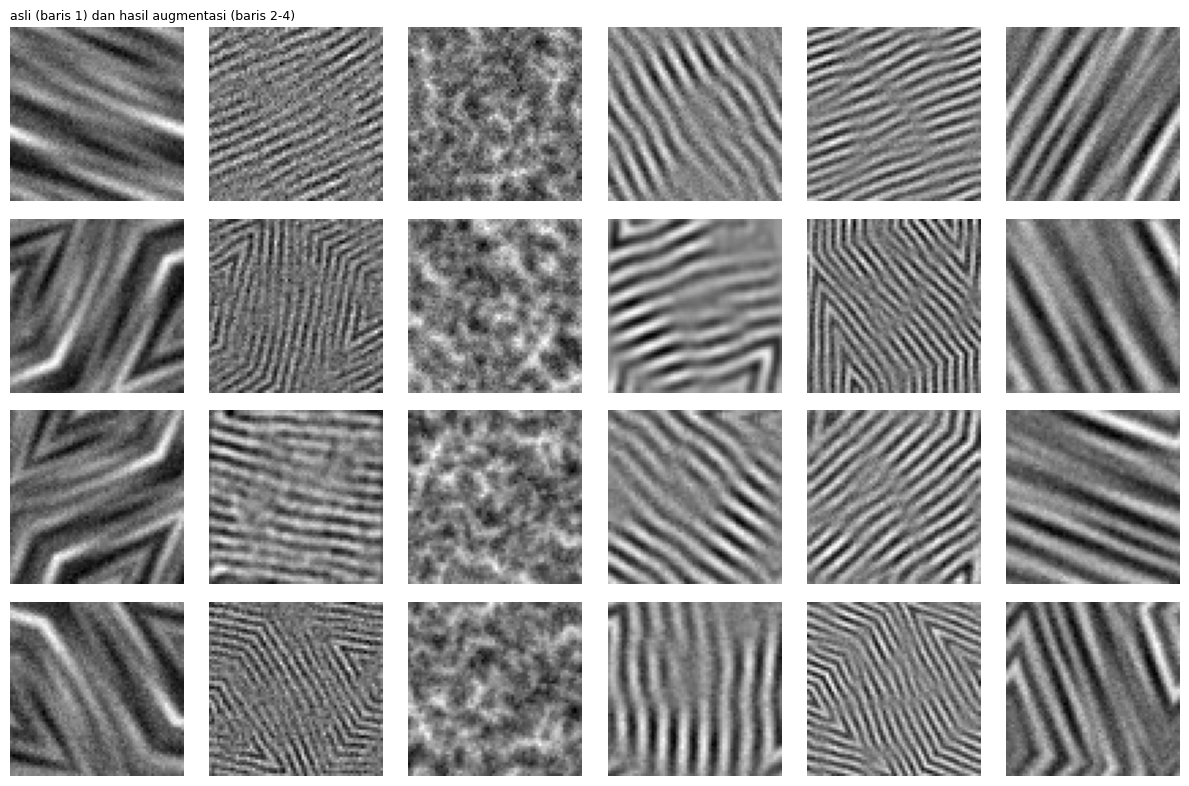

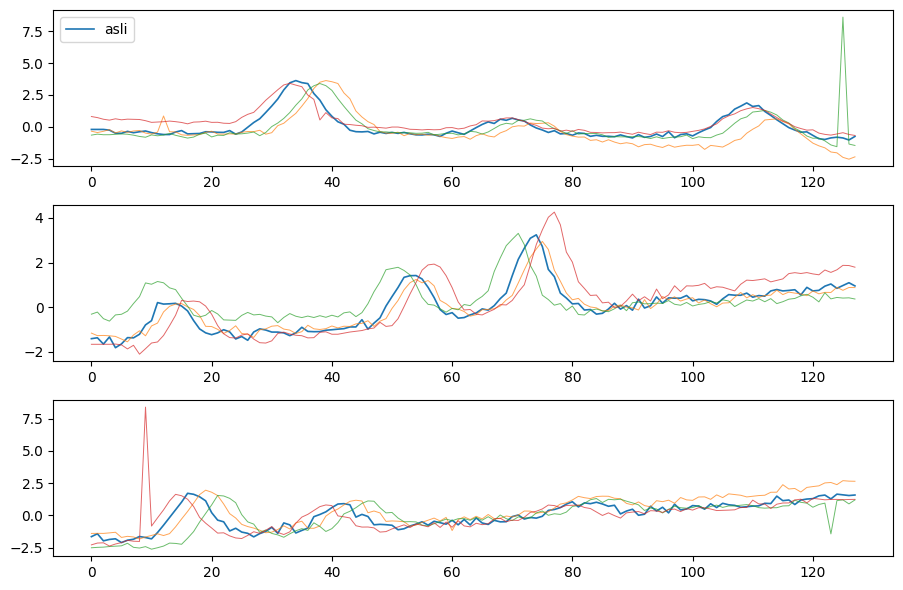

In [7]:
img = prep_images(img_raw); spec = prep_spectra(spec_raw)
print('gambar', img.shape, '| spektrum', spec.shape, '| rata-rata/std gambar:', img.mean().round(3), img.std().round(3))

xi = torch.from_numpy(img[:6]); xs = torch.from_numpy(spec[:3])
fig, ax = plt.subplots(4, 6, figsize=(12, 8))
for c in range(6):
    ax[0, c].imshow(img[c, 0], cmap='gray'); ax[0, c].axis('off')
    for r in (1, 2, 3):
        ax[r, c].imshow(aug_image(xi)[c, 0].numpy(), cmap='gray'); ax[r, c].axis('off')
ax[0, 0].set_title('asli (baris 1) dan hasil augmentasi (baris 2-4)', loc='left', fontsize=9)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/augmentasi_gambar.png', dpi=120); plt.show()

fig, ax = plt.subplots(3, 1, figsize=(9, 6))
for r in range(3):
    ax[r].plot(spec[r, 0], label='asli', lw=1.2)
    for _ in range(3): ax[r].plot(aug_spec(xs)[r, 0].numpy(), lw=.7, alpha=.7)
ax[0].legend(); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/augmentasi_spektrum.png', dpi=120); plt.show()

## 4. Representasi tanpa label (checklist #31)
Dua encoder (CNN untuk gambar, CNN-1D untuk spektrum) dilatih bersama dengan InfoNCE: (1) dua tampilan teraugmentasi dari gambar yang sama harus dekat, (2) sama untuk spektrum, (3) gambar dan spektrum dari sampel yang sama harus dekat (lintas modalitas). Tidak memakai label apa pun.

- [ ] Pelatihan selesai dan loss turun

epoch 01/20 | loss gambar 4.861 | spektrum 4.073 | lintas-modalitas 5.156
epoch 02/20 | loss gambar 3.964 | spektrum 3.318 | lintas-modalitas 4.462
epoch 03/20 | loss gambar 3.753 | spektrum 2.669 | lintas-modalitas 4.449
epoch 04/20 | loss gambar 3.647 | spektrum 2.380 | lintas-modalitas 4.487
epoch 05/20 | loss gambar 3.544 | spektrum 2.250 | lintas-modalitas 4.512
epoch 06/20 | loss gambar 3.458 | spektrum 2.177 | lintas-modalitas 4.531
epoch 07/20 | loss gambar 3.394 | spektrum 2.109 | lintas-modalitas 4.546
epoch 08/20 | loss gambar 3.316 | spektrum 2.064 | lintas-modalitas 4.571
epoch 09/20 | loss gambar 3.262 | spektrum 2.016 | lintas-modalitas 4.578
epoch 10/20 | loss gambar 3.207 | spektrum 1.971 | lintas-modalitas 4.597
epoch 11/20 | loss gambar 3.153 | spektrum 1.951 | lintas-modalitas 4.603
epoch 12/20 | loss gambar 3.060 | spektrum 1.929 | lintas-modalitas 4.618
epoch 13/20 | loss gambar 3.043 | spektrum 1.914 | lintas-modalitas 4.624
epoch 14/20 | loss gambar 3.006 | spek

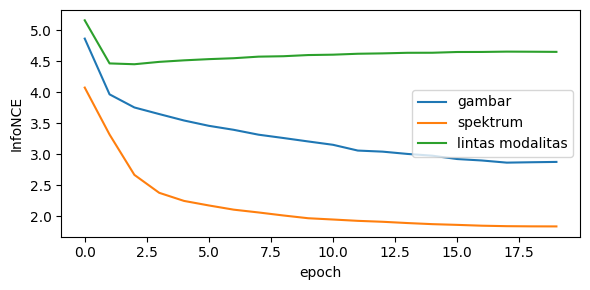

embedding gambar (36000, 128) | spektrum (36000, 128) | ada NaN: False


In [8]:
emb_file = f'{OUT_DIR}/embeddings.npz'
if (not RETRAIN) and os.path.exists(emb_file):
    e = np.load(emb_file); hi, hs = e['hi'], e['hs']; print('embedding dimuat dari', emb_file)
else:
    t0 = time.time()
    models, hist = train_contrastive(img, spec, epochs=EPOCHS, spe=SPE, batch=BATCH)
    print('waktu pelatihan: %.1f menit' % ((time.time() - t0) / 60))
    torch.save({k: m.state_dict() for k, m in models.items()}, f'{OUT_DIR}/encoders.pt')
    hi, hs = extract_embeddings(models, img, spec)
    np.savez(emb_file, hi=hi, hs=hs)
    plt.figure(figsize=(6, 3)); plt.plot(hist[:, 0], label='gambar'); plt.plot(hist[:, 1], label='spektrum'); plt.plot(hist[:, 2], label='lintas modalitas')
    plt.xlabel('epoch'); plt.ylabel('InfoNCE'); plt.legend(); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/kurva_loss_kontrastif.png', dpi=130); plt.show()
print('embedding gambar', hi.shape, '| spektrum', hs.shape, '| ada NaN:', bool(np.isnan(hi).any() or np.isnan(hs).any()))

## 5. Fusi dua modalitas (checklist #33)
Fitur gabungan = embedding gambar + embedding spektrum (tiap blok distandardisasi dan diberi bobot variansi sama), lalu PCA. Untuk analisis kehilangan informasi, dibuat juga fitur gambar saja dan spektrum saja.

In [9]:
Z_fused = make_features([hi, hs], n_pca=N_PCA)
Z_img = make_features([hi], n_pca=N_PCA)
Z_spec = make_features([hs], n_pca=N_PCA)
print('fusi', Z_fused.shape, '| gambar saja', Z_img.shape, '| spektrum saja', Z_spec.shape)

fusi (36000, 32) | gambar saja (36000, 32) | spektrum saja (36000, 32)


## 6. Jumlah klaster (checklist #32)
Lima kriteria pada fitur gabungan: silhouette, Davies-Bouldin, siku inertia KMeans, BIC GMM, dan stabilitas (ARI antar KMeans pada subsampel 80% yang berbeda). Jumlah klaster diusulkan lewat suara terbanyak; boleh diisi manual di `K_FINAL`.

- [ ] Tabel dan grafik kriteria  - [ ] `K_FINAL` ditentukan dan alasannya dicatat

k= 2 | sil 0.282 | DB 1.194 | BIC -2272992 | stabilitas 0.309
k= 3 | sil 0.335 | DB 1.259 | BIC -3185861 | stabilitas 0.690
k= 4 | sil 0.417 | DB 1.184 | BIC -3778396 | stabilitas 0.841
k= 5 | sil 0.482 | DB 0.861 | BIC -3804401 | stabilitas 0.795
k= 6 | sil 0.428 | DB 1.152 | BIC -3874902 | stabilitas 0.837
k= 7 | sil 0.345 | DB 1.433 | BIC -3913851 | stabilitas 0.763
k= 8 | sil 0.339 | DB 1.380 | BIC -3956510 | stabilitas 0.694
k= 9 | sil 0.265 | DB 1.561 | BIC -3995441 | stabilitas 0.714
k=10 | sil 0.259 | DB 1.566 | BIC -4016562 | stabilitas 0.712
k=11 | sil 0.213 | DB 1.737 | BIC -4043347 | stabilitas 0.747
k=12 | sil 0.213 | DB 1.678 | BIC -4052249 | stabilitas 0.745
k=13 | sil 0.180 | DB 1.825 | BIC -4082992 | stabilitas 0.830
k=14 | sil 0.174 | DB 1.796 | BIC -4101001 | stabilitas 0.713
k=15 | sil 0.178 | DB 1.752 | BIC -4102827 | stabilitas 0.778
 k   inertia  silhouette  davies_bouldin  calinski_harabasz          bic  stabilitas_ARI
 2 52181.109       0.282           1.194   

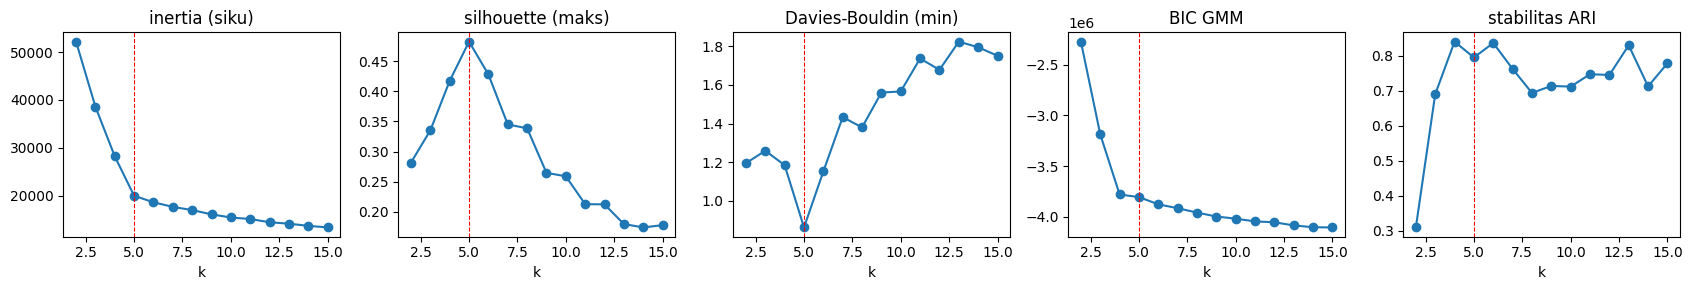

In [10]:
ks = list(range(K_MIN, K_MAX + 1))
df_k, votes, k_suggest = select_k(Z_fused, ks)
df_k.to_csv(f'{OUT_DIR}/kriteria_jumlah_klaster.csv', index=False)
print(df_k.round(3).to_string(index=False)); print('\nSuara tiap kriteria:', votes); print('Usulan k:', k_suggest)

fig, ax = plt.subplots(1, 5, figsize=(17, 3))
for a, col, t in zip(ax, ['inertia', 'silhouette', 'davies_bouldin', 'bic', 'stabilitas_ARI'],
                     ['inertia (siku)', 'silhouette (maks)', 'Davies-Bouldin (min)', 'BIC GMM', 'stabilitas ARI']):
    a.plot(df_k['k'], df_k[col], marker='o'); a.set_title(t); a.set_xlabel('k'); a.axvline(k_suggest, color='r', ls='--', lw=.8)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/kriteria_jumlah_klaster.png', dpi=130); plt.show()

In [11]:
K_FINAL = None                     # isi angka untuk menimpa usulan, mis. K_FINAL = 6
K = K_FINAL or k_suggest
print('Jumlah klaster yang dipakai:', K)

Jumlah klaster yang dipakai: 5


## 7. Perbandingan metode clustering (checklist #31-32)
KMeans, GMM, dan DEC (deep clustering). Tanpa label, perbandingan memakai metrik internal, stabilitas antar seed (ARI), dan seberapa besar klaster terkait mikroskop (NMI; idealnya rendah).

In [12]:
SEEDS = [0, 1, 2]
methods = {'KMeans': cluster_kmeans, 'GMM': cluster_gmm, 'DEC': cluster_dec}
labs, rows = {}, []
for name, fn in methods.items():
    t0 = time.time(); runs = [fn(Z_fused, K, seed=s) for s in SEEDS]
    labs[name] = runs; m = internal_metrics(Z_fused, runs[0])
    sizes = np.bincount(runs[0], minlength=K) / len(runs[0])
    rows.append(dict(metode=name, silhouette=m['silhouette'], davies_bouldin=m['davies_bouldin'], calinski_harabasz=m['calinski_harabasz'],
                     stabilitas_ARI=pairwise_ari(runs), NMI_mikroskop=normalized_mutual_info_score(runs[0], mik_id),
                     klaster_terkecil=sizes.min(), klaster_terbesar=sizes.max()))
    print(f'{name}: selesai dalam {time.time() - t0:.0f} detik')
tab = pd.DataFrame(rows).set_index('metode'); tab.to_csv(f'{OUT_DIR}/perbandingan_metode.csv')
print(tab.round(3).to_string())

names = list(methods); agree = pd.DataFrame([[adjusted_rand_score(labs[a][0], labs[b][0]) for b in names] for a in names], index=names, columns=names)
print('\nKesepakatan antar metode (ARI):'); print(agree.round(3).to_string())

KMeans: selesai dalam 4 detik
GMM: selesai dalam 8 detik
DEC: selesai dalam 89 detik
        silhouette  davies_bouldin  calinski_harabasz  stabilitas_ARI  NMI_mikroskop  klaster_terkecil  klaster_terbesar
metode                                                                                                                  
KMeans       0.482           0.861          22748.316           1.000          0.000             0.102             0.279
GMM          0.304           1.541          13004.971           0.834          0.002             0.128             0.342
DEC          0.482           0.861          22748.316           1.000          0.000             0.102             0.279

Kesepakatan antar metode (ARI):
        KMeans    GMM    DEC
KMeans   1.000  0.752  1.000
GMM      0.752  1.000  0.752
DEC      1.000  0.752  1.000


## 8. Analisis modalitas (checklist #33)
Apa yang hilang bila hanya satu modalitas dipakai? Klaster dari gambar saja, spektrum saja, dan fusi dibandingkan satu sama lain, dengan fitur mentah sebagai pembanding.

In [13]:
lab_f = cluster_kmeans(Z_fused, K); lab_i = cluster_kmeans(Z_img, K); lab_s = cluster_kmeans(Z_spec, K); lab_r = cluster_kmeans(Z_raw, K)
rep = pd.DataFrame({
    'ARI vs fusi': [1.0, adjusted_rand_score(lab_i, lab_f), adjusted_rand_score(lab_s, lab_f), adjusted_rand_score(lab_r, lab_f)],
    'NMI vs mikroskop': [normalized_mutual_info_score(l, mik_id) for l in (lab_f, lab_i, lab_s, lab_r)],
    'stabilitas ARI (3 seed)': [pairwise_ari([cluster_kmeans(Z, K, seed=s) for s in SEEDS]) for Z in (Z_fused, Z_img, Z_spec, Z_raw)]},
    index=['fusi gambar+spektrum', 'gambar saja', 'spektrum saja', 'fitur mentah (PCA)'])
print(rep.round(3).to_string())
print('\nARI gambar-saja vs spektrum-saja:', round(adjusted_rand_score(lab_i, lab_s), 3))
ct = pd.crosstab(lab_i, lab_s); print('\nTabel silang klaster gambar-saja (baris) x spektrum-saja (kolom):'); print(ct.to_string())
rep.to_csv(f'{OUT_DIR}/analisis_modalitas.csv')

                      ARI vs fusi  NMI vs mikroskop  stabilitas ARI (3 seed)
fusi gambar+spektrum        1.000               0.0                    1.000
gambar saja                 0.964               0.0                    1.000
spektrum saja               0.836               0.0                    1.000
fitur mentah (PCA)          0.790               0.0                    0.861

ARI gambar-saja vs spektrum-saja: 0.809

Tabel silang klaster gambar-saja (baris) x spektrum-saja (kolom):
col_0     0     1     2     3     4
row_0                              
0         0    31     0  4426  3971
1       156  9994    35    69    70
2         0     0  8651    56    41
3      3656     0     0     0     0
4      4821    20     1     1     1


## 9. Visualisasi (checklist #34)
UMAP (atau t-SNE bila umap-learn tidak terpasang) pada fitur gabungan, diwarnai klaster dan mikroskop. Klaster yang baik tidak terpisah hanya karena mikroskop.

umap-learn tidak tersedia ( ModuleNotFoundError ), pakai t-SNE. Pasang dengan: python -m pip install umap-learn


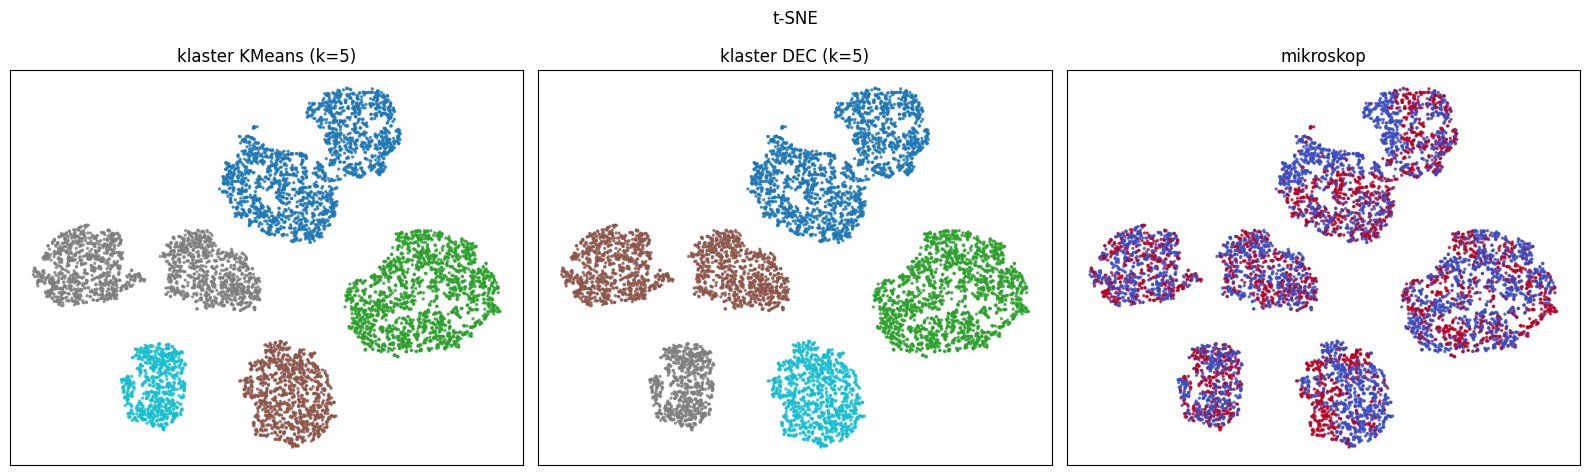

In [14]:
sel = np.random.RandomState(SEED).choice(len(Z_fused), min(N_VIS, len(Z_fused)), replace=False)
try:
    import umap
    emb2 = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(Z_fused[sel]); how = 'UMAP'
except Exception as e:
    from sklearn.manifold import TSNE
    print('umap-learn tidak tersedia (', type(e).__name__, '), pakai t-SNE. Pasang dengan: python -m pip install umap-learn')
    sel = sel[:8000]; emb2 = TSNE(2, perplexity=30, random_state=SEED, init='pca').fit_transform(Z_fused[sel]); how = 't-SNE'
lab_vis = labs['KMeans'][0][sel]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for a, c, t, cm in [(ax[0], lab_vis, f'klaster KMeans (k={K})', 'tab10'), (ax[1], labs['DEC'][0][sel], f'klaster DEC (k={K})', 'tab10'),
                    (ax[2], mik_id[sel], 'mikroskop', 'coolwarm')]:
    sc = a.scatter(emb2[:, 0], emb2[:, 1], c=c, s=2, cmap=cm, alpha=.7); a.set_title(t); a.set_xticks([]); a.set_yticks([])
plt.suptitle(how); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/visualisasi_{how}.png', dpi=130); plt.show()

## 10. Keluaran `cluster.csv` (checklist #34)
Pilih metode final. Default: metode dengan peringkat rata-rata terbaik pada stabilitas ARI dan silhouette; boleh ditimpa lewat `FINAL_METHOD`.

In [15]:
rank = tab[['stabilitas_ARI', 'silhouette']].rank(ascending=False).mean(1)
FINAL_METHOD = None                # isi 'KMeans', 'GMM', atau 'DEC' untuk menimpa
final = FINAL_METHOD or rank.idxmin()
print('Metode final:', final); print(rank.round(2).to_string())
labels = labs[final][0]
# nomor klaster diurutkan menurut ukuran (hanya kosmetik; ARI tidak terpengaruh)
order = pd.Series(labels).value_counts().index.tolist(); remap = {c: i for i, c in enumerate(order)}
labels = np.array([remap[c] for c in labels])

out = pd.DataFrame({'id_sampel': meta['id_sampel'].to_numpy(), 'cluster': labels.astype(int)})
out.to_csv('../../cluster.csv', index=False)
chk = pd.read_csv('../../cluster.csv')
assert list(chk.columns) == ['id_sampel', 'cluster'] and len(chk) == len(meta) and chk['id_sampel'].is_unique
assert chk['cluster'].dtype.kind == 'i' and chk['cluster'].notna().all()
print('cluster.csv:', chk.shape, '| jumlah klaster:', chk['cluster'].nunique()); print(chk['cluster'].value_counts().sort_index().to_string()); chk.head()

C:\Users\HP\AppData\Local\Temp\ipykernel_33204\1880759443.py:1: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  rank = tab[['stabilitas_ARI', 'silhouette']].rank(ascending=False).mean(1)


Metode final: KMeans
metode
KMeans    1.5
GMM       3.0
DEC       1.5
cluster.csv: (36000, 2) | jumlah klaster: 5
cluster
0    10043
1     8685
2     8637
3     4979
4     3656


,id_sampel,cluster
0,S966119,2
1,S315633,1
2,S805122,0
3,S467543,1
4,S475842,1


## Ringkasan Tugas 3: Clustering Multimodal Tipe Material

**Data.** 36.000 sampel berisi gambar 64×64 dan spektrum 128 titik, tanpa label, dari dua mikroskop (M1 21.636, M2 14.364). Tidak ada NaN. Brightness gambar berbeda antar mikroskop (rata-rata 127,8 vs 146,1), dan sekitar 74,9% spektrum mengandung minimal satu spike atau derau ekstrem.

**Pendekatan.**
1. Praproses: z-score per gambar dan per spektrum, buang spike, isi NaN.
2. Representasi tanpa label: CNN (gambar) dan CNN-1D (spektrum) dilatih bersama dengan InfoNCE selama 20 epoch. Augmentasi meniru distorsi di soal (rotasi, skala, brightness, geser spektrum, baseline, spike).
3. Fusi: embedding gambar dan spektrum digabung lalu direduksi dengan PCA ke 32 dimensi.
4. Pemilihan jumlah klaster dengan 5 kriteria (silhouette, Davies-Bouldin, siku inertia, BIC GMM, stabilitas ARI).
5. Perbandingan KMeans, GMM, dan DEC.

**Jumlah klaster.** Dipilih K = 5. Pada k = 5, silhouette tertinggi (0,482) dan Davies-Bouldin terendah (0,861). Stabilitas ARI tertinggi ada di k = 4 (0,841) dan k = 6 (0,837), sedangkan k = 5 mencapai 0,795. BIC terus turun sehingga tidak informatif untuk menentukan k.

**Perbandingan metode (k = 5):**

| Metode | Silhouette | Davies-Bouldin | Stabilitas ARI | NMI vs mikroskop |
|---|---|---|---|---|
| KMeans | 0,482 | 0,861 | 1,000 | 0,000 |
| GMM | 0,304 | 1,541 | 0,834 | 0,002 |
| DEC | 0,482 | 0,861 | 1,000 | 0,000 |

KMeans dan DEC menghasilkan klaster identik (ARI antar keduanya 1,0), sedangkan GMM lebih rendah (ARI dengan KMeans 0,752). Metode final: **KMeans**.

**Analisis modalitas.** Klaster dari gambar saja sangat mirip dengan hasil fusi (ARI 0,964), sedangkan spektrum saja lebih rendah (0,836). Fitur mentah (PCA) hanya 0,790 dan kurang stabil (stabilitas 0,861 dibanding 1,000 pada fitur hasil representasi). Klaster gambar dan klaster spektrum cukup sejalan (ARI 0,809). Pada semua representasi, NMI terhadap mikroskop mendekati 0, jadi klaster tidak ditentukan oleh perbedaan mikroskop.

**Keluaran.** cluster.csv berisi 36.000 baris (id_sampel, cluster) dengan 5 klaster: 10.043, 8.685, 8.637, 4.979, dan 3.656 sampel.

**Keterbatasan.** Karena tidak ada label, kualitas hanya dinilai dengan metrik internal, stabilitas, dan NMI terhadap mikroskop, sehingga ARI sebenarnya terhadap label tersembunyi belum diketahui. DEC tidak mengubah hasil KMeans, jadi kontribusinya tidak terlihat. Loss lintas-modalitas tidak turun selama pelatihan (5,156 di epoch 1, 4,648 di epoch 20), sehingga penyelarasan gambar dan spektrum kemungkinan belum optimal.